<a href="https://colab.research.google.com/github/shrinidhisj1/4IK25CS192_DAV_LAB/blob/main/4IK25CS192_EXP_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment-09

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Load the dataset

In [2]:
df = pd.read_csv('/content/Iris.csv')
print(df.head())
print("Shape",df.shape)
print("Missing value:",df.isnull().sum().sum())
print(df["Species"].value_counts)

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Shape (150, 6)
Missing value: 0
<bound method IndexOpsMixin.value_counts of 0         Iris-setosa
1         Iris-setosa
2         Iris-setosa
3         Iris-setosa
4         Iris-setosa
            ...      
145    Iris-virginica
146    Iris-virginica
147    Iris-virginica
148    Iris-virginica
149    Iris-virginica
Name: Species, Length: 150, dtype: object>


feature(X) and target(y)

In [3]:
X = df.drop(["Id", "Species"], axis=1)
y = df["Species"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [5]:
model = DecisionTreeClassifier(criterion="gini",max_depth=3,random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

Predict on test data

In [6]:
y_pred=model.predict(X_test)

Evaluate the model

In [7]:
print("Accuracy:", accuracy_score(y_test, y_pred))
ce=confusion_matrix(y_test,y_pred)
print("\nConfusion Matrix:\n", ce)
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9666666666666667

Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
Classification Report:
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



Visualize the decision tree

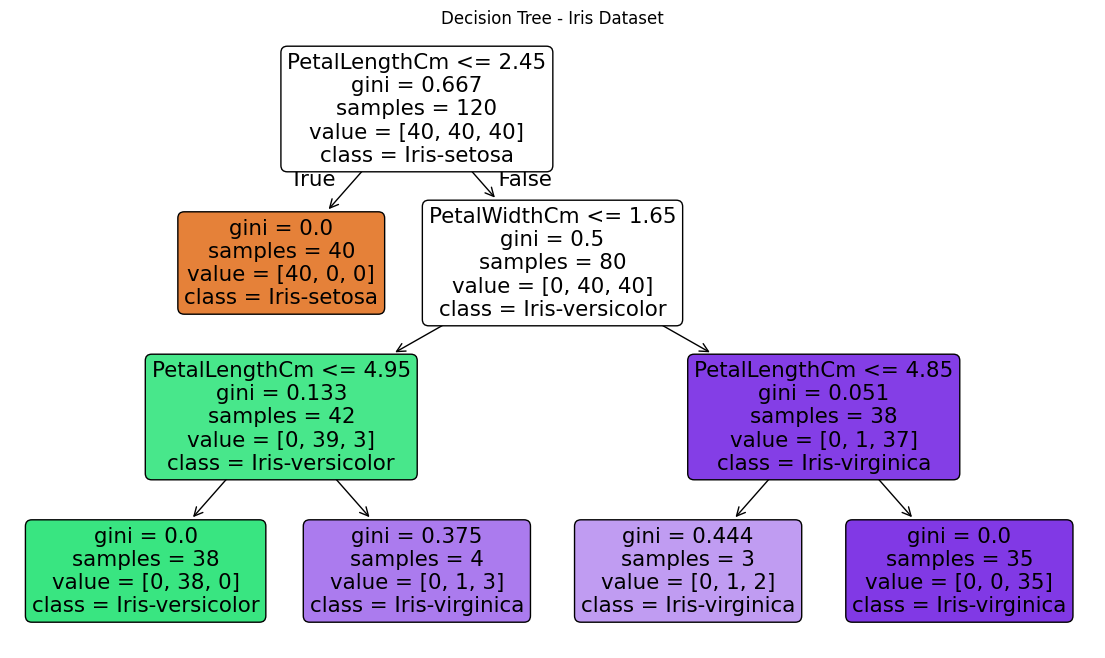

In [8]:
plt.figure(figsize=(14, 8))
plot_tree(model, filled=True, feature_names=X.columns, class_names=model.classes_, rounded=True)
plt.title("Decision Tree - Iris Dataset")
plt.show()

Visualize the Confusion matrix

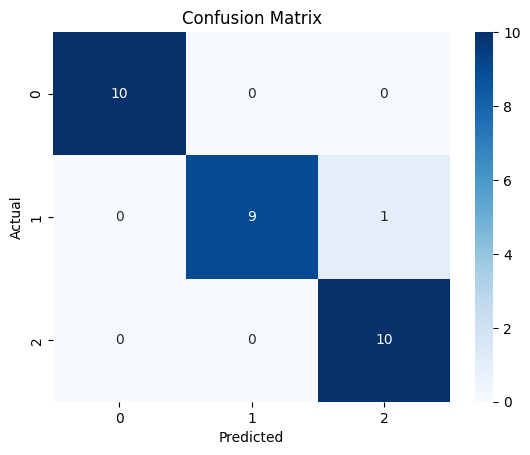

In [9]:
sns.heatmap(ce, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

Feature importance (which measurement helps the tree most)

In [10]:
print("\nFeature Importance:")
print(pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False))


Feature Importance:
PetalLengthCm    0.579077
PetalWidthCm     0.420923
SepalWidthCm     0.000000
SepalLengthCm    0.000000
dtype: float64
